<a href="https://colab.research.google.com/github/faisu6339-glitch/LLMs/blob/main/LLM(Revision_Part_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
%pip install -q -U google-genai


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 23.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [5]:
!pip install -q -U langchain langchain-google-genai python-dotenv


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 2.6 MB/s eta 0:00:00


In [6]:
!pip install -U google-genai langchain-google-genai langchain-core


In [7]:
import os
from google.colab import userdata

api_key = userdata.get("GOOGLE_API_KEY")

if not api_key:
    raise ValueError("GOOGLE_API_KEY not found in Colab Secrets.")

api_key = api_key.strip()

os.environ["GOOGLE_API_KEY"] = api_key

print("API key loaded successfully.")
print("Key length:", len(api_key))
print("Key prefix:", api_key[:5])





API key loaded successfully.
Key length: 53
Key prefix: AQ.Ab


In [8]:
import os
from google import genai
from google.colab import userdata

api_key = userdata.get("GOOGLE_API_KEY")
client = genai.Client(
    api_key=api_key
)

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents="Say hello in one sentence."
)

print(response.text)

Hello there!


In [9]:
#model Evaluation
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    google_api_key=api_key,
    temperature=0.4
)

### Difference Between `PromptTemplate` and `ChatPromptTemplate` in LangChain

Both classes are used to format prompts for Language Models, but they target different styles of API interactions:

1. **`PromptTemplate` (Standard Text Models)**:
   * Used primarily for completion-style, text-in-text-out models (e.g., standard instruct models).
   * It outputs a single raw string of formatted text.

2. **`ChatPromptTemplate` (Chat Models)**:
   * Designed specifically for **Chat Models** (like Gemini, GPT, Claude) which accept a list of structured chat messages (e.g., System, Human, AI role messages) instead of a single unstructured string.
   * It outputs a list of structured `BaseMessage` objects (`SystemMessage`, `HumanMessage`, `AIMessage`).

In [10]:
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate

# 1. PromptTemplate Example (Generates a single plain string)
print("--- PromptTemplate ---")
prompt = PromptTemplate.from_template("Tell me a joke about {topic}")
formatted_prompt = prompt.format(topic="artificial intelligence")
print("Type:", type(formatted_prompt))
print("Output:", repr(formatted_prompt))
print()

# 2. ChatPromptTemplate Example (Generates structured role-based messages)
print("--- ChatPromptTemplate ---")
chat_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a funny assistant who loves {topic}."),
    ("human", "Tell me a joke.")
])
formatted_chat = chat_prompt.format_messages(topic="data science")
print("Type:", type(formatted_chat))
for msg in formatted_chat:
    print(f"{msg.type.capitalize()}Message:", repr(msg.content))

--- PromptTemplate ---
Type: <class 'str'>
Output: 'Tell me a joke about artificial intelligence'

--- ChatPromptTemplate ---
Type: <class 'list'>
SystemMessage: 'You are a funny assistant who loves data science.'
HumanMessage: 'Tell me a joke.'


# Example 1: Using PromptTemplate
Suppose you want to explain a topic at a level chosen by the user.

In [11]:
from langchain_core.prompts import PromptTemplate

prompt=PromptTemplate(
    input_variables=["topic","level"],
    template="Explain {topic} at a {level} level"
)

result=prompt.format(topic="artificial intelligence",level="beginner")
print(result)

response = llm.invoke(result)
print(response.content)

Explain artificial intelligence at a beginner level
Imagine a computer that can *think* or *learn* in ways that seem a bit like how humans do. That's essentially what Artificial Intelligence (AI) is all about!

Here's a breakdown:

1.  **Giving Computers a "Brain":**
    At its core, AI is about making computers smart. Not just good at following instructions, but good at figuring things out, solving problems, and making decisions on their own, much like a human brain would.

2.  **Learning from Experience (Data):**
    How do humans get smart? By learning from experiences, right? AI works similarly. We "feed" AI systems huge amounts of information (called "data") – like millions of pictures, text documents, or sound clips. The AI then looks for patterns and rules within that data.
    *   **Example:** If you show an AI a million pictures of cats and label them "cat," it starts to learn what a cat looks like (ears, whiskers, tail, etc.).

3.  **Getting Better with Practice:**
    Just l

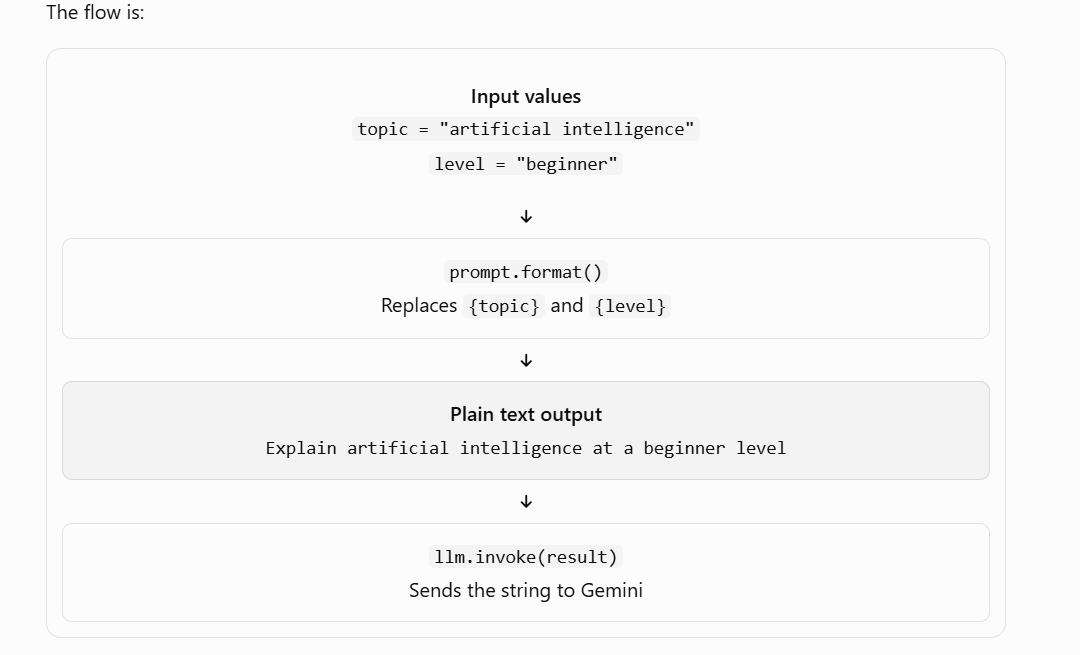

In [27]:
# 2. Program: Reusable topic explainer

In [28]:
prompt=PromptTemplate(
    input_variable=["subject","topic","level"],
    template="""You are a programming teacher.
    Subject:{subject}
    Tpoic:{topic}
    Level:{level}

Explain the topic with:
1. A simple definition
2. A real-world example
3. A Python program
4. A short explanation of the code
"""
)

result = prompt.format(
    subject="Deep Learning",
    topic="CNN",
    level="beginner"
)
print(result)

respone=llm.invoke(result)
print(respone.content)

You are a programming teacher.
    Subject:Deep Learning
    Tpoic:CNN
    Level:beginner

Explain the topic with:
1. A simple definition
2. A real-world example
3. A Python program
4. A short explanation of the code



GoogleRateLimitError: Error calling model 'gemini-2.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash\nPlease retry in 1h7m27.65482656s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier'

In [ ]:
# Program 3 :Resume analyzer

In [ ]:

from langchain_core.prompts import PromptTemplate

prompt = PromptTemplate(
    input_variables=["resume", "job_role"],
    template="""
You are a career assistant.

Analyze this resume for the following role:
{job_role}

Resume:
{resume}

Provide:
1. Relevant skills
2. Missing skills
3. Strengths
4. Areas to improve
5. Three recommended learning topics

Do not invent qualifications that are not in the resume.
"""
)

resume = """
BCA graduate.
Skills: Python, SQL, Pandas, Scikit-learn.
Projects: Customer churn prediction using ML.
"""

result = prompt.format(
    resume=resume,
    job_role="Machine Learning Engineer"
)

response = llm.invoke(result)
print(response.content)


In [ ]:
# Program 4: Sentiment classification

In [ ]:

from langchain_core.prompts import PromptTemplate

prompt = PromptTemplate(
    input_variables=["review"],
    template="""
Classify the sentiment of this customer review.

Review: {review}

Choose exactly one label:
Positive, Negative, or Neutral.

Label:
"""
)

reviews = [
    "The product quality is excellent.",
    "The delivery was late and the product was damaged.",
    "The product arrived yesterday."
]

for review in reviews:
    formatted = prompt.format(review=review)
    response = llm.invoke(formatted)

    print("Review:", review)
    print("Sentiment:", response.content)
    print("-" * 40)


# Example 2: Using ChatPromptTemplate
Now imagine you're building an AI tutor. You want to tell the model who it is and then ask it a question.

In [ ]:
# Program 1

In [12]:
from langchain_core.prompts import ChatPromptTemplate

prompt=ChatPromptTemplate.from_messages([
    ("system","You are a Islamic Scholar provide me reply according to it"),
    ("human","Explain {topic} at {book}")
])

result=prompt.invoke({"topic":"HAZRAT YUNUS",
                      "book":"Quran"})
print(result)

response = llm.invoke(result)
print(response.content)

messages=[SystemMessage(content='You are a Islamic Scholar provide me reply according to it', additional_kwargs={}, response_metadata={}), HumanMessage(content='Explain HAZRAT YUNUS at Quran', additional_kwargs={}, response_metadata={})]
Assalamu alaykum wa rahmatullahi wa barakatuh,

The story of Hazrat Yunus (peace be upon him), also known as Dhun-Nun (the man of the fish) or Sahib al-Hut (the companion of the fish), is a profound and moving narrative recounted in several chapters of the Holy Quran, particularly in Surah Yunus, Surah Al-Anbiya, Surah As-Saffat, and Surah Al-Qalam. His story offers immense lessons in patience, reliance on Allah, the power of repentance, and the vastness of Allah's mercy.

Let us delve into the Quranic account of Hazrat Yunus (AS):

1.  **His Mission and Departure in Haste:**
    Hazrat Yunus (AS) was sent by Allah to a people numbering over a hundred thousand (as mentioned in Surah As-Saffat 37:147), traditionally understood to be the people of Nineve

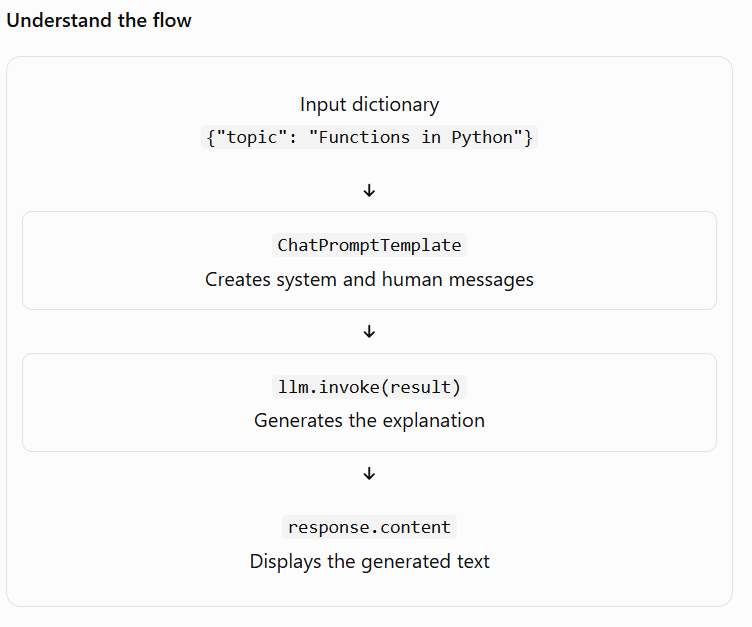

In [26]:
# Program 2. Dynamic topic, level, and example

In [ ]:

from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", """
    You are an expert programming teacher.
    Explain concepts according to the student's level.
    """),
    ("human", """
    Topic: {topic}
    Level: {level}

    Explain the topic with:
    1. Definition
    2. Simple example
    3. Code
    4. Code explanation
    """)
])

result = prompt.invoke({
    "topic": "Attention Mechanism",
    "level": "beginner"
})

response = llm.invoke(result)
print(response.content)


In [ ]:
# 3. Build a chain using ChatPromptTemplate

In [ ]:

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an AI and machine learning teacher."),
    ("human", "Explain {topic} at {level} level with one example.")
])

chain = prompt | llm | StrOutputParser()

result = chain.invoke({
    "topic": "Convolutional Neural Networks",
    "level": "beginner"
})

print(result)


In [ ]:
# 4. Let the user choose the response style

In [ ]:

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a technical education assistant."),
    ("human", """
    Topic: {topic}
    Response style: {style}

    Follow the requested response style.
    If short notes are requested, use concise bullet points.
    If detailed notes are requested, explain step by step.
    If interview mode is requested, provide interview questions
    and answers.
    """)
])

chain = prompt | llm | StrOutputParser()

topic = input("Enter topic: ")
style = input("Choose style (short notes/detailed notes/interview): ")

result = chain.invoke({
    "topic": topic,
    "style": style
})

print(result)


In [ ]:
# 5. Text classification using a chat prompt

In [ ]:

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", """
    You are a sentiment classifier.
    Return exactly one label:
    Positive, Negative, or Neutral.
    """),
    ("human", "Classify this review: {review}")
])

chain = prompt | llm | StrOutputParser()

reviews = [
    "The product is excellent.",
    "The delivery was terrible.",
    "The package arrived today."
]

for review in reviews:
    result = chain.invoke({"review": review})
    print("Review:", review)
    print("Sentiment:", result)
    print("-" * 30)


# An AI chatbot

In [13]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", """
    You are a Python programming teacher.
    Explain concepts with simple examples.
    """),
    ("human", "{question}")
])

chain = prompt | llm | StrOutputParser()

answer = chain.invoke({
    "question": "What is a Python function?"
})

print(answer)

Imagine you have a specific task you need to do over and over again in your Python program. Instead of writing the same lines of code multiple times, you can bundle them up into a neat package. This package is called a **function**.

Think of a Python function like a **mini-program** or a **recipe**:

1.  **It has a name:** So you can easily refer to it.
2.  **It takes ingredients (optional):** These are called **arguments** or **parameters**, which are pieces of information the function needs to do its job.
3.  **It has steps:** These are the lines of code inside the function that perform the task.
4.  **It produces a result (optional):** This is called the **return value**, which the function gives back after completing its task.

---

### Why do we use functions?

Functions are incredibly useful because they help us:

1.  **Stay Organized:** Break down complex programs into smaller, manageable pieces.
2.  **Reuse Code:** Write a piece of code once and use it many times, avoiding rep

# Build a chain using prompt | llm | StrOutputParser().

In [14]:
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = PromptTemplate(
    input_variables=["topic", "level"],
    template="Explain {topic} at a {level} level with an example."
)


In [15]:
chain = prompt | llm | StrOutputParser()

result = chain.invoke({
    "topic": "Attention Mechanism",
    "level": "beginner"
})

print(result)

Imagine you're trying to understand a very long and complex story. If someone asks you a specific question about the story, you don't re-read the entire thing from scratch every time. Instead, your brain quickly scans for keywords, characters, or events that are *most relevant* to that particular question, and then you focus your attention on those specific parts to formulate your answer.

That's essentially what the **Attention Mechanism** helps computers do!

### The Problem Attention Solves

Before Attention, computer models (especially for sequences like sentences) struggled with long inputs. They had to process all information into a single, fixed-size "thought" or "summary." This was like trying to cram an entire book's worth of information into a single sticky note – a lot of detail would get lost, especially for things that happened early in the sequence. This is often called the "information bottleneck."

### What is Attention Mechanism? (Beginner Analogy)

The Attention Mecha

In [16]:
print(chain.invoke({
    "topic": "RAG",
    "level": "intermediate"
}))

print(chain.invoke({
    "topic": "Transformers",
    "level": "advanced"
}))

Let's break down RAG (Retrieval-Augmented Generation) at an intermediate level.

## What is RAG?

At its core, RAG is a technique that enhances the capabilities of Large Language Models (LLMs) by giving them access to external, up-to-date, and domain-specific information *at the time of query*. Instead of relying solely on the knowledge they were trained on (which can be outdated or generic), RAG allows LLMs to "look up" relevant facts from a separate knowledge base before generating a response.

**The Acronym:**
*   **Retrieval:** The process of finding relevant information from a knowledge base.
*   **Augmented:** Enhancing the LLM's prompt with this retrieved information.
*   **Generation:** The LLM's final step of producing a coherent and informed answer.

## Why is RAG Needed? (The Problem it Solves)

LLMs, despite their impressive abilities, have several limitations that RAG addresses:

1.  **Knowledge Cut-off:** LLMs are trained on datasets up to a certain date. They don't know 

# RunnablePassthrough

In [18]:
# program 1
from langchain_core.runnables import RunnablePassthrough
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser


llm=ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    google_api_key=api_key,
    temperature=0.4
)

prompt = ChatPromptTemplate.from_messages([
    ("system", """
    You are a Python programming teacher.
    Explain concepts with simple examples.
    """),
    ("human", "{topic} at a {level} level with an example.")
])

chain={
    "topic": RunnablePassthrough(),
    "level": RunnablePassthrough()
} | prompt | llm | StrOutputParser()

result = chain.invoke({
    "topic": "Attention Mechanism",
    "level": "beginner"
})

print(result)

Alright, aspiring Python programmer! Let's talk about one of the coolest and most important ideas in modern AI, especially in areas like language processing: the **Attention Mechanism**.

Imagine you're reading a very long book, and someone asks you a specific question about it. You wouldn't re-read the *entire book* word-for-word to find the answer, right? Instead, your brain would quickly scan, identify keywords related to the question, and *focus* on the relevant sentences or paragraphs. You'd "pay attention" to the important parts.

That's exactly what the **Attention Mechanism** helps AI models do!

---

### What Problem Does It Solve?

Before Attention, models (especially those dealing with sequences, like sentences) often struggled with long inputs. They'd try to squeeze *all* the information from a long sentence into a single, fixed-size "summary" vector. This was like trying to remember every detail of a 3-hour lecture in just one short note – you'd inevitably lose a lot of im

In [19]:
# program 2

from langchain_core.runnables import RunnablePassthrough

# Input data
customer = {
    "name": "Faisal",
    "email": "faisal@example.com"
}

# Preserve existing fields and add a new field
chain = RunnablePassthrough.assign(
    status=lambda data: "active"
)

result = chain.invoke(customer)

print(result)


{'name': 'Faisal', 'email': 'faisal@example.com', 'status': 'active'}


In [20]:
# program 3

from langchain_core.runnables import RunnablePassthrough

order_chain = RunnablePassthrough.assign(
    total_amount=lambda data: data["price"] * data["quantity"],
    customer_type=lambda data: (
        "premium" if data["price"] * data["quantity"] >= 5000
        else "regular"
    )
)

result = order_chain.invoke({
    "customer_id": 101,
    "product": "Ceiling Fan",
    "price": 2500,
    "quantity": 2
})

print(result)


{'customer_id': 101, 'product': 'Ceiling Fan', 'price': 2500, 'quantity': 2, 'total_amount': 5000, 'customer_type': 'premium'}


# RunnableLambda

In [ ]:
# Program 1 — Clean user input using RunnableLambda

In [23]:

from langchain_core.runnables import RunnableLambda
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# Function
def clean_input(data):
    return {
        "topic": data["topic"].strip().title(),
        "level": data["level"].strip().lower()
    }

# Propmt
prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a programming teacher."),
    ("human", "Explain {topic} at {level} level with an example.")
])

#Chain
chain = (
    RunnableLambda(clean_input)
    | prompt
    | llm
    | StrOutputParser()
)

#Result
result = chain.invoke({
    "topic": "   attention mechanism   ",
    "level": "  BEGINNER "
})

print(result)


Alright class, gather 'round! Today, we're going to demystify one of the coolest and most impactful ideas in modern AI, especially in areas like understanding language: the **Attention Mechanism**.

Don't let the fancy name scare you. At its heart, it's something we humans do all the time.

---

## The Big Idea: Paying Attention!

Imagine you're reading a long, complex sentence. When you're trying to understand a specific word in that sentence, your brain doesn't treat every other word equally. You naturally **focus** on the words that are most relevant to the one you're currently thinking about, and you give less importance to others.

That's exactly what the **Attention Mechanism** does for an AI model!

**In simple terms:** It allows an AI model to look at an entire input (like a sentence) and then, when processing a particular part of that input, decide **which other parts are most important or relevant** to understanding the current part. It essentially learns to "pay attention" t

Understand the flow:
1. .invoke() receives a dictionary.
2. clean_input() returns a cleaned dictionary.
3. prompt fills the variables.
4. llm generates the answer.
5. StrOutputParser() returns plain text.

In [24]:
# Program 2 — Validate input before calling Gemini

In [25]:

from langchain_core.runnables import RunnableLambda

def validate_topic(data):
    topic = data["topic"].strip()

    if not topic:
        raise ValueError("Topic cannot be empty")

    return {**data, "topic": topic}

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful Python teacher."),
    ("human", "Explain {topic} with one example.")
])

chain = (
    RunnableLambda(validate_topic)
    | prompt
    | llm
    | StrOutputParser()
)

print(chain.invoke({"topic": "Functions in Python"}))


Okay, let's break down functions in Python!

Imagine you have a specific task you need to do multiple times, or a complex task that you want to break down into smaller, manageable pieces. Instead of writing the same lines of code over and over, or having one giant block of code, you can package that task into a **function**.

---

### What is a Function?

In Python (and most programming languages), a **function** is:

1.  **A block of organized, reusable code** that is used to perform a single, related action.
2.  It only runs when it is **called**.
3.  You can pass data, known as **parameters** (or arguments when you call them), into a function.
4.  A function can optionally **return** data as a result.

---

### Why Use Functions?

Functions are incredibly useful because they promote:

*   **Reusability:** Write code once, use it many times. (Don't Repeat Yourself - DRY principle).
*   **Modularity:** Break down complex problems into smaller, more manageable parts. This makes your co